In [1]:
import torch
import geospaNN
import numpy as np
import time
import pandas as pd
import seaborn as sns

import matplotlib
import matplotlib.pyplot as plt

R callback write-console: Loading required package: BRISC
  
R callback write-console: Loading required package: RANN
  
R callback write-console: Loading required package: parallel
  
R callback write-console: Loading required package: rdist
  
R callback write-console: Loading required package: matrixStats
  
R callback write-console: Loading required package: pbapply
  
R callback write-console: The ordering of inputs x (covariates) and y (response) in BRISC_estimation has been changed BRISC 1.0.0 onwards.
  Please check the new documentation with ?BRISC_estimation.
  


R package: BRISC installed


/opt/anaconda3/envs/geomed2026/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def f1(X): return 10 * np.sin(np.pi * 2 * X)


sigma = 1
phi = 0.1
tau = 0.01
theta = torch.tensor([sigma, phi / np.sqrt(2), tau])

p = 1;
funXY = f1

n = 1000
nn = 20
batch_size = 50

torch.manual_seed(2025)
_, _, _, _, X = geospaNN.Simulation(n, p, nn, funXY, torch.tensor([1, 5, 0.01]), range=[0, 1])
X = X.reshape(-1,1)
X = (X - X.min())/(X.max() - X.min())
torch.manual_seed(2025)
_, _, coord, cov, corerr = geospaNN.Simulation(n, p, nn, funXY, theta, range=[0, 1])
Y = funXY(X).reshape(-1) + corerr

torch.manual_seed(2024)
np.random.seed(0)
data_train, data_val, data_test = geospaNN.split_data(X, Y, coord, neighbor_size=nn,
                                                      test_proportion=0.2)

/var/folders/_w/4z9wsc814_v5pp5ywhnpmlw80000gn/T/ipykernel_85165/858311744.py:1: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  def f1(X): return 10 * np.sin(np.pi * 2 * X)
/var/folders/_w/4z9wsc814_v5pp5ywhnpmlw80000gn/T/ipykernel_85165/858311744.py:1: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  def f1(X): return 10 * np.sin(np.pi * 2 * X)


In [3]:
torch.manual_seed(2025)
mlp_nn = torch.nn.Sequential(
    torch.nn.Linear(p, 5),
    torch.nn.ReLU(),
    torch.nn.Linear(5, 1)
)
trainer_nn = geospaNN.nn_train(mlp_nn, lr=0.01, min_delta=0.001)
training_log = trainer_nn.train(data_train, data_val, data_test)
theta0 = geospaNN.theta_update(mlp_nn(data_train.x).squeeze() - data_train.y, data_train.pos, neighbor_size=20)

INFO: Early stopping
End at epoch80
---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 600 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


  
   
Please check the new documentation with ?BRISC_estimation.
  


Theta estimated as
[ 4.47407376 29.24566062  0.06124933]


In [4]:
torch.manual_seed(2025)
mlp_linear = torch.nn.Sequential(
    torch.nn.Linear(p, 1),
)
model_linear = geospaNN.nngls(p=p, neighbor_size=nn, coord_dimensions=2, mlp=mlp_linear, theta = torch.tensor(theta0))
trainer_linear = geospaNN.nngls_train(model_linear, lr=0.01, min_delta=0.001)
training_log = trainer_linear.train(data_train, data_val, data_test,
                                        Update_init=10, Update_step=5)

---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 600 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


  
   
Please check the new documentation with ?BRISC_estimation.
  


Theta estimated as
[3.65745797e+01 1.28536130e+01 1.00000000e-03]
to
[3.65745797e+01 1.28536130e+01 1.00000000e-03]
---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 600 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


  
   
Please check the new documentation with ?BRISC_estimation.
  


Theta estimated as
[3.62142186e+01 1.29069222e+01 1.00000000e-03]
to
[3.62142186e+01 1.29069222e+01 1.00000000e-03]
---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 600 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


...

Theta estimated as
[3.06353090e+01 1.38828356e+01 1.00000000e-03]
to
[3.06353090e+01 1.38828356e+01 1.00000000e-03]
---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 600 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


  
   
Please check the new documentation with ?BRISC_estimation.
  


Theta estimated as
[3.01523026e+01 1.39833717e+01 1.00000000e-03]
to
[3.01523026e+01 1.39833717e+01 1.00000000e-03]
---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 600 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


  
   
Please check the new documentation with ?BRISC_estimation.
  


Theta estimated as
[2.96623351e+01 1.40897588e+01 1.00000000e-03]
to
[2.96623351e+01 1.40897588e+01 1.00000000e-03]


In [5]:
torch.manual_seed(2025)
mlp_l1_n5 = torch.nn.Sequential(
    torch.nn.Linear(p, 5),
    torch.nn.ReLU(),
    torch.nn.Linear(5, 1)
)
nngls_l1_n5 = geospaNN.nngls(p=p, neighbor_size=nn, coord_dimensions=2, mlp=mlp_l1_n5, theta=torch.tensor(theta0))
trainer_l1_n5 = geospaNN.nngls_train(nngls_l1_n5, lr=0.1, min_delta=0.001)
training_log = trainer_l1_n5.train(data_train, data_val, data_test,
                                   Update_init=20, Update_step=5, seed = 2024)

INFO: Early stopping
End at epoch14


In [6]:
torch.manual_seed(2025)
mlp_l1_n20 = torch.nn.Sequential(
    torch.nn.Linear(p, 20),
    torch.nn.ReLU(),
    torch.nn.Linear(20, 1)
)
nngls_l1_n20 = geospaNN.nngls(p=p, neighbor_size=nn, coord_dimensions=2, mlp=mlp_l1_n20, 
                              theta=torch.tensor(theta0))
trainer_l1_n20 = geospaNN.nngls_train(nngls_l1_n20, lr=0.01, min_delta=0.001)
training_log = trainer_l1_n20.train(data_train, data_val, data_test,
                                    Update_init=20, Update_step=5, seed = 2024)

---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 600 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


  
   
Please check the new documentation with ?BRISC_estimation.
  


Theta estimated as
[5.84852082e+00 3.55991294e+01 4.78329461e-03]
to
[5.84852082e+00 3.55991294e+01 4.78329461e-03]
---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 600 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


  
   
Please check the new documentation with ?BRISC_estimation.
  


Theta estimated as
[5.57655236e+00 3.47519651e+01 1.30276769e-02]
to
[5.57655236e+00 3.47519651e+01 1.30276769e-02]
---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 600 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


...

Theta estimated as
[ 1.35388151 16.0496375   0.15320208]
to
[ 1.35388151 16.0496375   0.15320208]
---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 600 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


  
   
Please check the new documentation with ?BRISC_estimation.
  


Theta estimated as
[ 1.29750003 14.48490919  0.14974171]
to
[ 1.29750003 14.48490919  0.14974171]
---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 600 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


  
   
Please check the new documentation with ?BRISC_estimation.
  


Theta estimated as
[ 1.10927282 14.82298014  0.17315261]
to
[ 1.10927282 14.82298014  0.17315261]


In [7]:
torch.manual_seed(2025)
mlp_l1_n50 = torch.nn.Sequential(
    torch.nn.Linear(p, 50),
    torch.nn.ReLU(),
    torch.nn.Linear(50, 1)
)
nngls_l1_n50 = geospaNN.nngls(p=p, neighbor_size=nn, coord_dimensions=2, mlp=mlp_l1_n50, 
                              theta=torch.tensor(theta0))
trainer_l1_n50 = geospaNN.nngls_train(nngls_l1_n50, lr=0.1, min_delta=0.001)
training_log = trainer_l1_n50.train(data_train, data_val, data_test,
                                    Update_init=10, Update_step=5, seed = 2024)

---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 600 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


  
   
Please check the new documentation with ?BRISC_estimation.
  


Theta estimated as
[ 2.31637454 31.98510728  0.07691934]
to
[ 2.31637454 31.98510728  0.07691934]
---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 600 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


  
   
Please check the new documentation with ?BRISC_estimation.
  


Theta estimated as
[ 1.22061694 30.18956081  0.0718476 ]
to
[ 1.22061694 30.18956081  0.0718476 ]
---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 600 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


  
   
Please check the new documentation with ?BRISC_estimation.
  


Theta estimated as
[ 0.59793982 16.61993682  0.14217215]
to
[ 0.59793982 16.61993682  0.14217215]
---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 600 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


  
   
Please check the new documentation with ?BRISC_estimation.
  


Theta estimated as
[ 0.27389971 11.23184665  0.39450947]
to
[ 0.27389971 11.23184665  0.39450947]
INFO: Early stopping
End at epoch28


In [8]:
torch.manual_seed(2025)
mlp_l2_n5_2 = torch.nn.Sequential(
    torch.nn.Linear(p, 5),
    torch.nn.ReLU(),
    torch.nn.Linear(5, 2),
    torch.nn.ReLU(),
    torch.nn.Linear(2, 1)
)
nngls_l2_n5_2 = geospaNN.nngls(p=p, neighbor_size=nn, coord_dimensions=2, mlp=mlp_l2_n5_2, theta=torch.tensor(theta0))
trainer_l2_n5_2 = geospaNN.nngls_train(nngls_l2_n5_2, lr=0.1, min_delta=0.001)
training_log = trainer_l2_n5_2.train(data_train, data_val, data_test,
                                     Update_init=10, Update_step=5, seed = 2024)

---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 600 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


  
   
Please check the new documentation with ?BRISC_estimation.
  


Theta estimated as
[ 1.62950111 31.5561666   0.15227763]
to
[ 1.62950111 31.5561666   0.15227763]
---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 600 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


  
   
Please check the new documentation with ?BRISC_estimation.
  


Theta estimated as
[ 1.15605801 19.96962793  0.26174073]
to
[ 1.15605801 19.96962793  0.26174073]
---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 600 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


  
   
Please check the new documentation with ?BRISC_estimation.
  


Theta estimated as
[ 1.04883867 19.55007272  0.24894385]
to
[ 1.04883867 19.55007272  0.24894385]
---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 600 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


  
   
Please check the new documentation with ?BRISC_estimation.
  


Theta estimated as
[ 1.07449658 14.38613805  0.22424403]
to
[ 1.07449658 14.38613805  0.22424403]
INFO: Early stopping
End at epoch26


In [19]:
torch.manual_seed(2025)
mlp_l2_n50_50 = torch.nn.Sequential(
    torch.nn.Linear(p, 50),
    torch.nn.ReLU(),
    torch.nn.Linear(50, 50),
    torch.nn.ReLU(),
    torch.nn.Linear(50, 1)
)
nngls_l2_n50_50 = geospaNN.nngls(p=p, neighbor_size=nn, coord_dimensions=2, mlp=mlp_l2_n50_50, theta=torch.tensor(theta0))
trainer_l2_n50_50 = geospaNN.nngls_train(nngls_l2_n50_50, lr=0.1, min_delta=0.001)
training_log = trainer_l2_n50_50.train(data_train, data_val, data_test,
                                       Update_init=10, Update_step=5, seed = 2024)

---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 600 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


  
   
Please check the new documentation with ?BRISC_estimation.
  


Theta estimated as
[0.21601399 9.16685949 0.19465449]
to
[0.21601399 9.16685949 0.19465449]
---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 600 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


  
   
Please check the new documentation with ?BRISC_estimation.
  


Theta estimated as
[ 1.012639  12.8826449  0.1834582]
to
[ 1.012639  12.8826449  0.1834582]
---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 600 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


...

Theta estimated as
[0.60114584 2.00450401 0.02750002]
to
[0.60114584 2.00450401 0.02750002]
---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 600 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


  
   
Please check the new documentation with ?BRISC_estimation.
  


Theta estimated as
[0.26790384 3.83765647 0.05181396]
to
[0.26790384 3.83765647 0.05181396]
---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 600 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


  
   
Please check the new documentation with ?BRISC_estimation.
  


Theta estimated as
[0.31042557 2.63310491 0.02992861]
to
[0.31042557 2.63310491 0.02992861]
INFO: Early stopping
End at epoch41


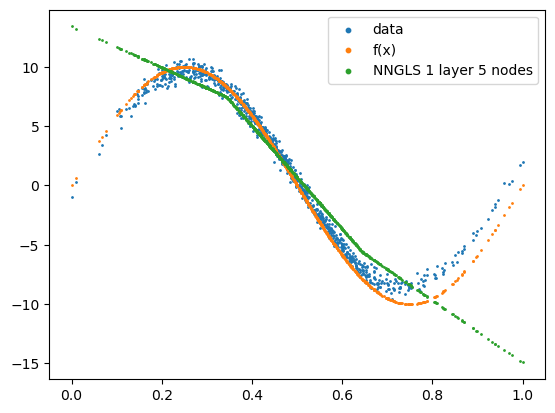

In [11]:
plt.clf()
plt.scatter(X.detach().numpy(), Y.detach().numpy(), s=1, label='data')
plt.scatter(X.detach().numpy(), funXY(X.detach().numpy()), s=1, label='f(x)')
plt.scatter(X.detach().numpy(), mlp_l1_n5(X).detach().numpy(), s=1, label='NNGLS 1 layer 5 nodes')
#plt.scatter(X.detach().numpy(), mlp_l1_n20(X).detach().numpy(), s=1, label='NNGLS 1 layer 20 nodes')
#plt.scatter(X.detach().numpy(), mlp_l1_n50(X).detach().numpy(), s=1, label='NNGLS 1 layer 50 nodes')
lgnd = plt.legend()
for handle in lgnd.legend_handles:
    handle.set_sizes([10.0])
plt.show()

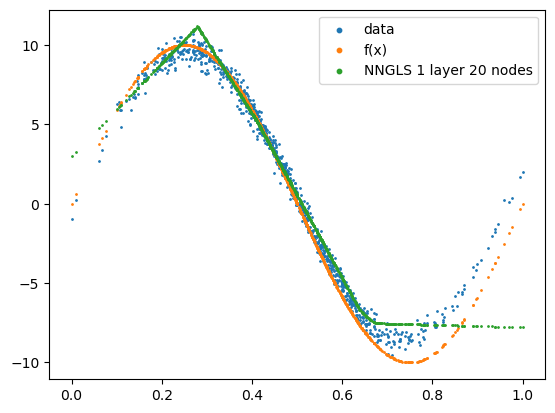

In [12]:
plt.clf()
plt.scatter(X.detach().numpy(), Y.detach().numpy(), s=1, label='data')
plt.scatter(X.detach().numpy(), funXY(X.detach().numpy()), s=1, label='f(x)')
#plt.scatter(X.detach().numpy(), mlp_l1_n5(X).detach().numpy(), s=1, label='NNGLS 1 layer 5 nodes')
plt.scatter(X.detach().numpy(), mlp_l1_n20(X).detach().numpy(), s=1, label='NNGLS 1 layer 20 nodes')
#plt.scatter(X.detach().numpy(), mlp_l1_n50(X).detach().numpy(), s=1, label='NNGLS 1 layer 50 nodes')
lgnd = plt.legend()
for handle in lgnd.legend_handles:
    handle.set_sizes([10.0])
plt.show()

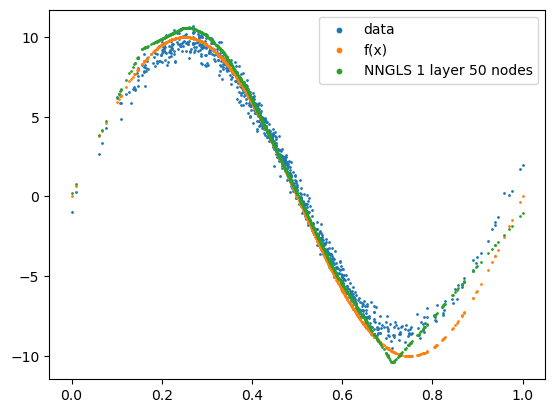

In [13]:
plt.clf()
plt.scatter(X.detach().numpy(), Y.detach().numpy(), s=1, label='data')
plt.scatter(X.detach().numpy(), funXY(X.detach().numpy()), s=1, label='f(x)')
#plt.scatter(X.detach().numpy(), mlp_l1_n5(X).detach().numpy(), s=1, label='NNGLS 1 layer 5 nodes')
#plt.scatter(X.detach().numpy(), mlp_l1_n20(X).detach().numpy(), s=1, label='NNGLS 1 layer 20 nodes')
plt.scatter(X.detach().numpy(), mlp_l1_n50(X).detach().numpy(), s=1, label='NNGLS 1 layer 50 nodes')
lgnd = plt.legend()
for handle in lgnd.legend_handles:
    handle.set_sizes([10.0])
plt.show()

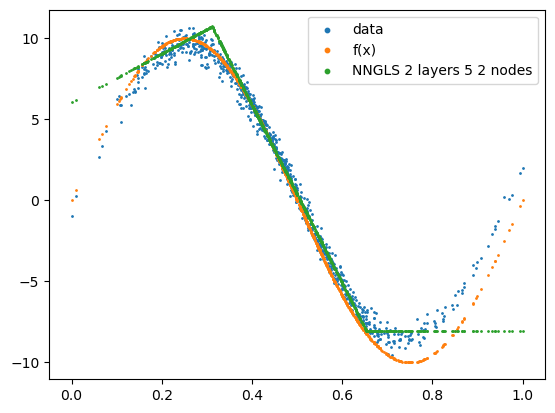

In [ ]:
plt.clf()
plt.scatter(X.detach().numpy(), Y.detach().numpy(), s=1, label='data')
plt.scatter(X.detach().numpy(), funXY(X.detach().numpy()), s=1, label='f(x)')
plt.scatter(X.detach().numpy(), mlp_l2_n5_2(X).detach().numpy(), s=1, label='NNGLS 2 layers 5 2 nodes')
#plt.scatter(X.detach().numpy(), mlp_l2_n50_50(X).detach().numpy(), s=1, label='NNGLS 2 layers 50 20 nodes')
lgnd = plt.legend()
for handle in lgnd.legend_handles:
    handle.set_sizes([10.0])
plt.show()

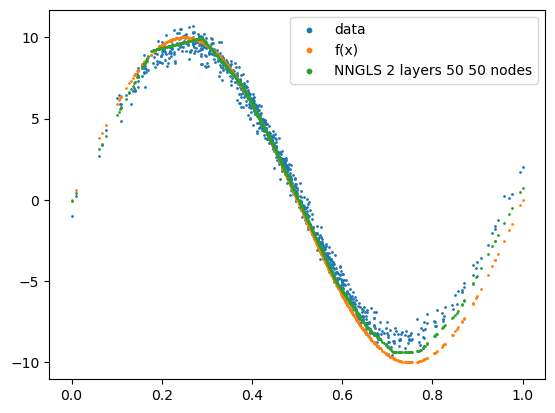

In [20]:
plt.clf()
plt.scatter(X.detach().numpy(), Y.detach().numpy(), s=1, label='data')
plt.scatter(X.detach().numpy(), funXY(X.detach().numpy()), s=1, label='f(x)')
#plt.scatter(X.detach().numpy(), mlp_l2_n5_2(X).detach().numpy(), s=1, label='NNGLS 2 layers 5 2 nodes')
plt.scatter(X.detach().numpy(), mlp_l2_n50_50(X).detach().numpy(), s=1, label='NNGLS 2 layers 50 50 nodes')
lgnd = plt.legend()
for handle in lgnd.legend_handles:
    handle.set_sizes([10.0])
plt.show()

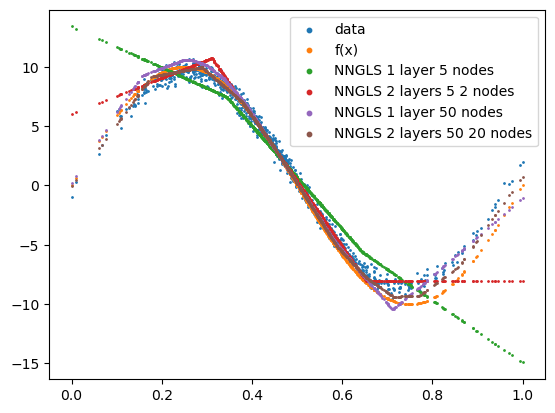

In [21]:
plt.clf()
plt.scatter(X.detach().numpy(), Y.detach().numpy(), s=1, label='data')
plt.scatter(X.detach().numpy(), funXY(X.detach().numpy()), s=1, label='f(x)')
plt.scatter(X.detach().numpy(), mlp_l1_n5(X).detach().numpy(), s=1, label='NNGLS 1 layer 5 nodes')
plt.scatter(X.detach().numpy(), mlp_l2_n5_2(X).detach().numpy(), s=1, label='NNGLS 2 layers 5 2 nodes')
plt.scatter(X.detach().numpy(), mlp_l1_n50(X).detach().numpy(), s=1, label='NNGLS 1 layer 50 nodes')
plt.scatter(X.detach().numpy(), mlp_l2_n50_50(X).detach().numpy(), s=1, label='NNGLS 2 layers 50 20 nodes')
lgnd = plt.legend()
for handle in lgnd.legend_handles:
    handle.set_sizes([10.0])
plt.show()